In [1]:
print("Hello*123566")

Hello*123566


In [2]:
!pip install playwright

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://packagefeedproxy.microsoft.io/pypi/simple/



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\v-yaalam\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
from playwright.sync_api import sync_playwright

with sync_playwright() as p:
    browser = p.chromium.launch(headless=False)

    page = browser.new_page()

    page.goto("https://example.com")

    print("Page title:", page.title())

    page.screenshot(path="example.png")

    browser.close()

Error: It looks like you are using Playwright Sync API inside the asyncio loop.
Please use the Async API instead.

In [4]:

from playwright.async_api import async_playwright

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=False)

    page = await browser.new_page()

    await page.goto("https://example.com")

    print("Page title:", await page.title())

    await page.screenshot(path="example.png")

    await browser.close()


NotImplementedError: 

In [5]:
!pip install chromium

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://packagefeedproxy.microsoft.io/pypi/simple/



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\v-yaalam\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [8]:
!python playwright_test.py

Page title: Example Domain
Screenshot saved successfully!


In [9]:

import subprocess
import sys

result = subprocess.run(
    [sys.executable, "playwright_test.py"],
    capture_output=True,
    text=True
)

print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)


STDOUT: Page title: Example Domain
Screenshot saved successfully!

STDERR: 


In [10]:
!python playwright_updated_name_screenshot.py

Page title: Microsoft – AI, Cloud, Productivity, Computing, Gaming & Apps
Screenshot saved: C:\Users\v-yaalam\Downloads\vscode_Dell_17-1\1.Python Learning\http_browser\screenshots\screenshot_2026-10-24_16-03-55-080269_b483c263.png


In [11]:

import subprocess
import sys

result = subprocess.run(
    [sys.executable, "playwright_updated_name_screenshot.py"],
    capture_output=True,
    text=True
)

print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)


STDOUT: Page title: Microsoft â€“ AI, Cloud, Productivity, Computing, Gaming & Apps
Screenshot saved: C:\Users\v-yaalam\Downloads\vscode_Dell_17-1\1.Python Learning\http_browser\screenshots\screenshot_2026-10-24_16-04-32-408806_2826fd38.png

STDERR: 


In [12]:
!python URL_update_manually.py

^C


In [13]:
import subprocess
import sys

subprocess.run(
    [sys.executable, "-m", "playwright", "install", "chromium"],
    check=True
)

CompletedProcess(args=['C:\\Users\\v-yaalam\\AppData\\Local\\Microsoft\\WindowsApps\\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\\python.exe', '-m', 'playwright', 'install', 'chromium'], returncode=0)

In [14]:

from pathlib import Path

script = '''
from playwright.sync_api import sync_playwright
from datetime import datetime
from pathlib import Path
from urllib.parse import urlparse
from uuid import uuid4
import sys

def main():
    url = sys.argv[1].strip()

    if not url.startswith(("http://", "https://")):
        url = "https://" + url

    screenshot_folder = Path("screenshots")
    screenshot_folder.mkdir(exist_ok=True)

    with sync_playwright() as p:
        browser = p.chromium.launch(headless=False)

        try:
            page = browser.new_page()

            print(f"Opening: {url}", flush=True)

            page.goto(
                url,
                wait_until="domcontentloaded",
                timeout=30000
            )

            print("Page title:", page.title(), flush=True)

            timestamp = datetime.now().strftime(
                "%Y-%m-%d_%H-%M-%S-%f"
            )

            website_name = urlparse(url).hostname or "website"
            website_name = "".join(
                c if c.isalnum() or c in "-_" else "_"
                for c in website_name
            )

            unique_id = uuid4().hex[:8]

            filename = (
                f"{website_name}_{timestamp}_{unique_id}.png"
            )

            screenshot_path = screenshot_folder / filename

            page.screenshot(
                path=str(screenshot_path),
                full_page=True
            )

            print(
                "Screenshot saved:",
                screenshot_path.resolve(),
                flush=True
            )

        finally:
            browser.close()

if __name__ == "__main__":
    main()
'''

Path("playwright_test1.py").write_text(
    script,
    encoding="utf-8"
)

print("Playwright script created successfully!")


Playwright script created successfully!


In [16]:

import subprocess
import sys

url = input("Enter website URL: ").strip()

if url:
    result = subprocess.run(
        [sys.executable, "playwright_test1.py", url],
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print("Error:", result.stderr)
else:
    print("Please enter a valid URL.")


Opening: https://youtube.com
Page title: YouTube
Screenshot saved: C:\Users\v-yaalam\Downloads\vscode_Dell_17-1\1.Python Learning\http_browser\screenshots\youtube_com_2026-10-24_16-09-26-864158_cdbdb2ca.png



Latest screenshot: youtube_com_2026-10-24_16-09-26-864158_cdbdb2ca.png


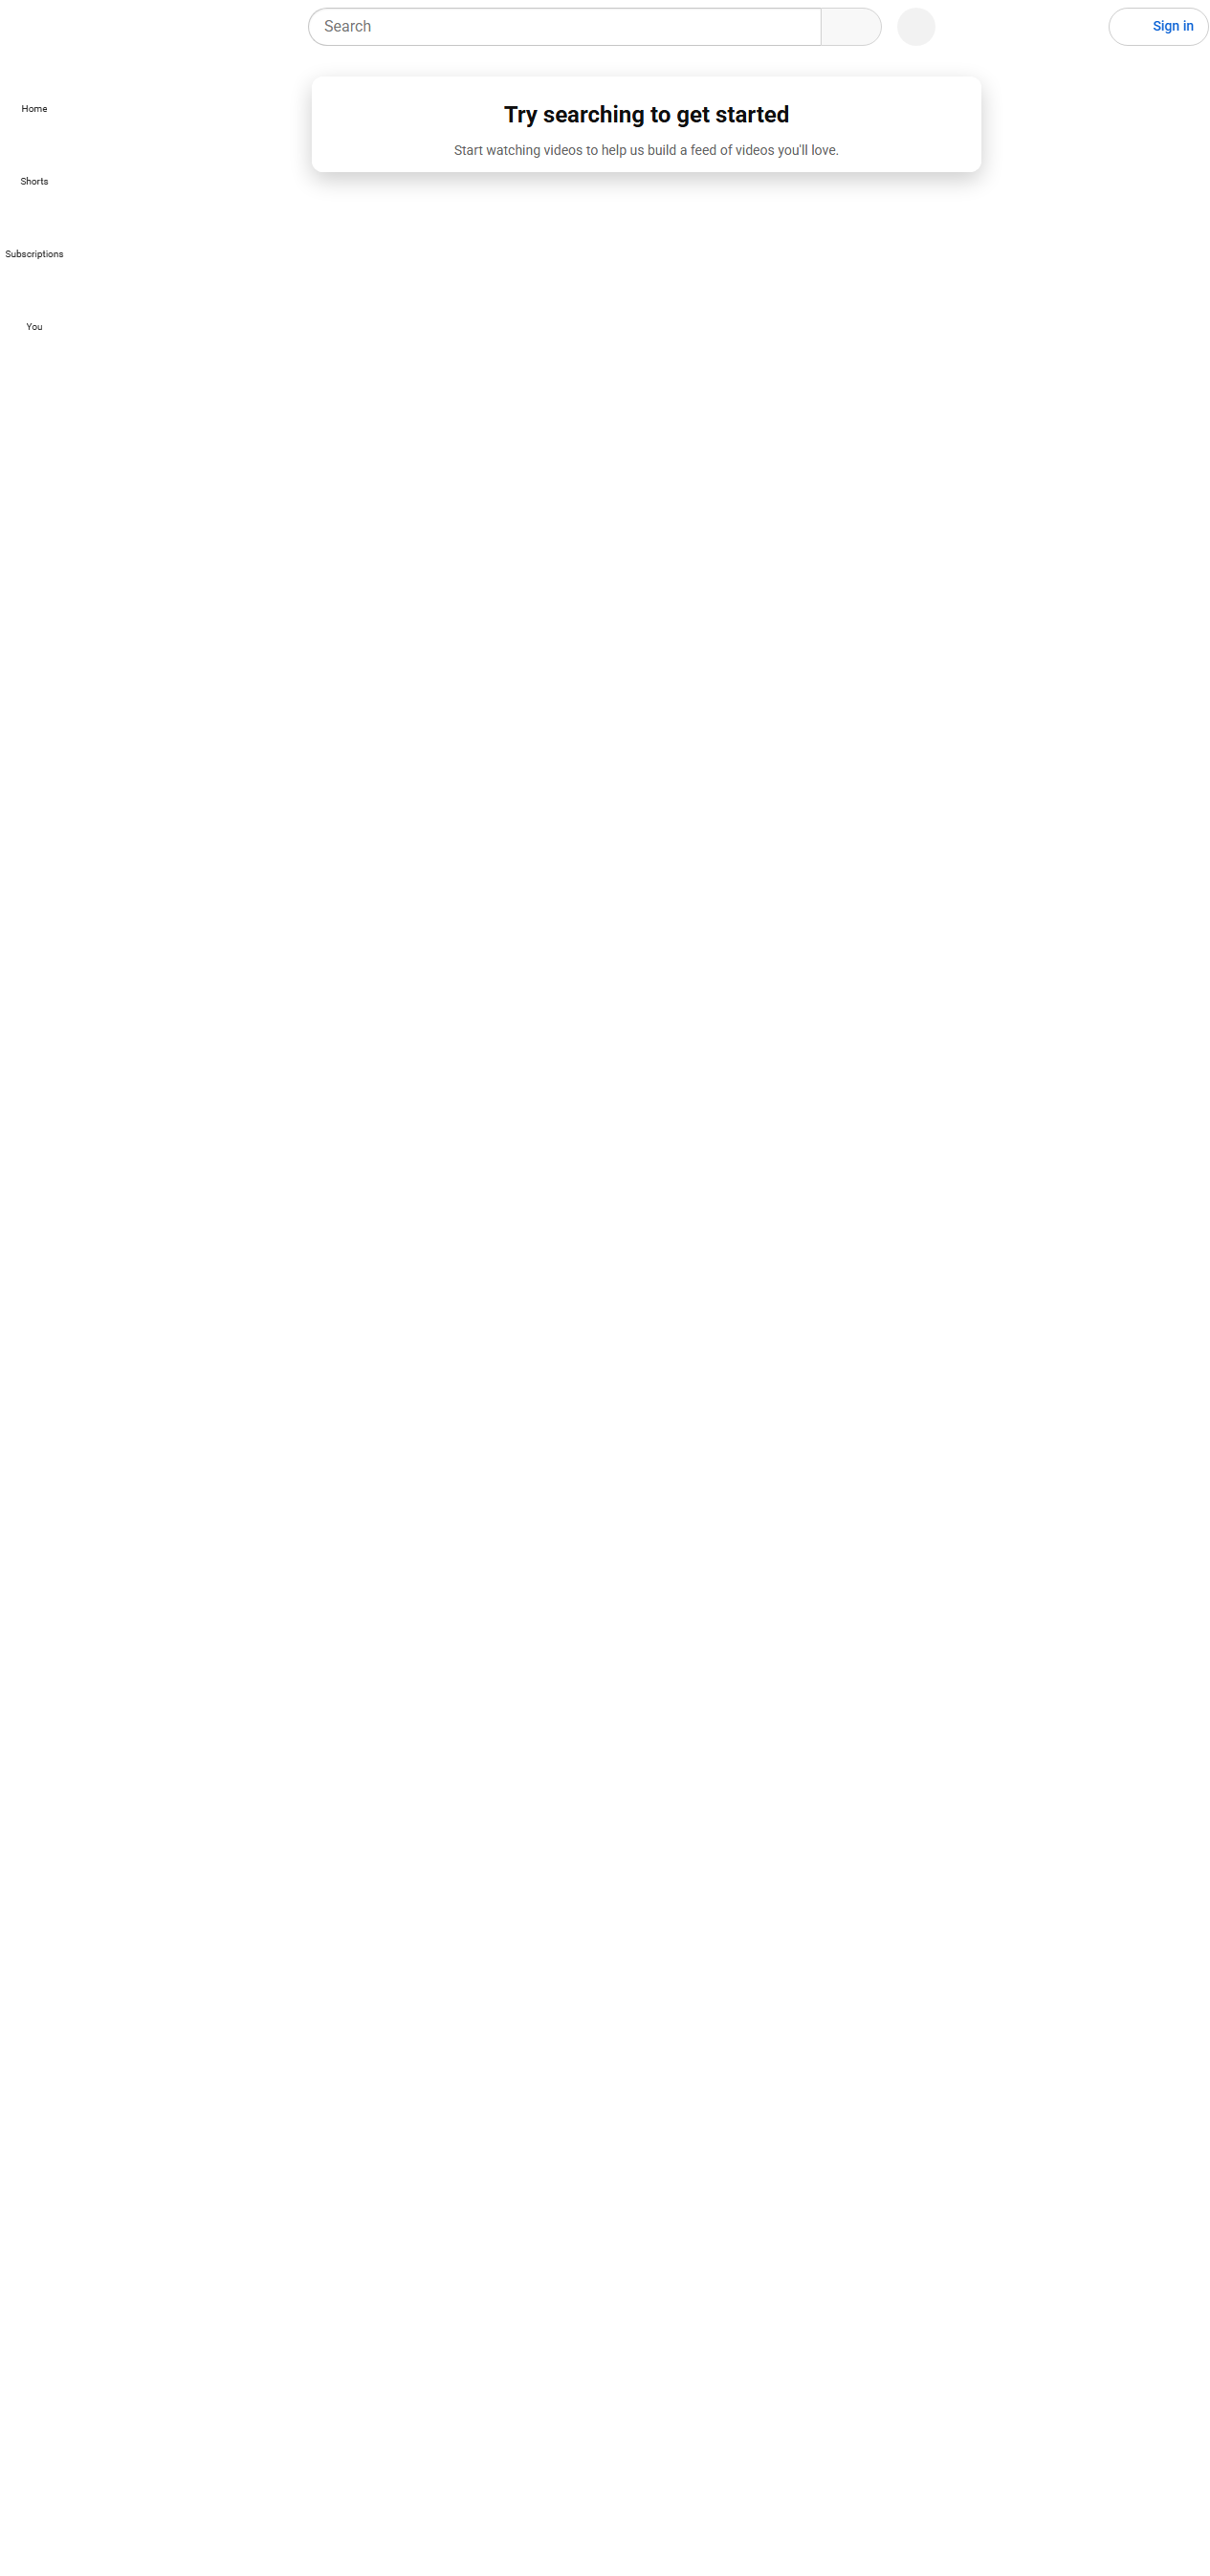

In [17]:

from pathlib import Path
from IPython.display import display, Image

screenshots = list(Path("screenshots").glob("*.png"))

if screenshots:
    latest = max(screenshots, key=lambda p: p.stat().st_mtime)
    print("Latest screenshot:", latest.name)
    display(Image(filename=str(latest)))
else:
    print("No screenshots found.")


You can run the same Playwright screenshot automation directly from your VS Code Jupyter Notebook (`.ipynb`). Since your Windows Jupyter kernel previously produced a `NotImplementedError`, the reliable approach is to execute Playwright in a separate Python process.

This solution will let you manually enter URLs, capture full-page screenshots, automatically name them using the date and time, and preserve all previous screenshots.

## Step 1: Install Playwright in Jupyter

Run this in your first notebook cell:

```
%pip install playwright
```

Then install Chromium in the next cell:

```
import subprocessimport syssubprocess.run(    [sys.executable, "-m", "playwright", "install", "chromium"],    check=True)
```

## Step 2: Create the Playwright script from Jupyter

Paste this entire code into your second notebook cell.

```
from pathlib import Pathscript = '''from playwright.sync_api import sync_playwrightfrom datetime import datetimefrom pathlib import Pathfrom urllib.parse import urlparsefrom uuid import uuid4import sysdef main():    url = sys.argv[1].strip()    if not url.startswith(("http://", "https://")):        url = "https://" + url    screenshot_folder = Path("screenshots")    screenshot_folder.mkdir(exist_ok=True)    with sync_playwright() as p:        browser = p.chromium.launch(headless=False)        try:            page = browser.new_page()            print(f"Opening: {url}", flush=True)            page.goto(                url,                wait_until="domcontentloaded",                timeout=30000            )            print("Page title:", page.title(), flush=True)
```

This creates a `playwright_test.py` file automatically in your notebook's working directory.

## Step 3: Manually enter the URL and capture a screenshot

Run this in your next Jupyter cell:

```
import subprocessimport sysurl = input("Enter website URL: ").strip()if url:    result = subprocess.run(        [sys.executable, "playwright_test.py", url],        capture_output=True,        text=True    )    print(result.stdout)    if result.returncode != 0:        print("Error:", result.stderr)else:    print("Please enter a valid URL.")
```

Every time you run this cell, you can enter a different URL. You don't need to recreate the script.

## Step 4: View your screenshots in Jupyter

Run this optional cell to display your most recent screenshot:

```
from pathlib import Pathfrom IPython.display import display, Imagescreenshots = list(Path("screenshots").glob("*.png"))if screenshots:    latest = max(screenshots, key=lambda p: p.stat().st_mtime)    print("Latest screenshot:", latest.name)    display(Image(filename=str(latest)))else:    print("No screenshots found.")
```

## Example workflow

JUPYTER NOTEBOOK OUTPUT — EXAMPLE

```
Enter website URL: github.com

Opening: https://github.com
Page title: GitHub · Build and ship software

Screenshot saved:
screenshots/github_com_2026-10-24_16-30-15-123456_a1b2c3d4.png
```

Your notebook's working directory will contain:

```
Project/
├── automation.ipynb
├── playwright_test.py
└── screenshots/
    ├── github_com_2026-10-24_16-30-15-123456_a1b2c3d4.png
    ├── google_com_2026-10-24_16-32-20-456789_e5f6a7b8.png
    └── microsoft_com_2026-10-24_16-35-10-789123_c9d0e1f2.png
```

Important: Your browser will open as a separate Chromium window. This requires a local desktop environment that supports launching a browser.

The advantage of this approach is that you can keep working entirely from Jupyter Notebook, manually enter new URLs, and save unlimited timestamped screenshots without encountering the earlier asyncio subprocess error.